# 05 · Diagnostics
**Study Smarter, Not Harder** · Member D (Auditor) · slide 7

Audit of the main controls model, **M3** in notebook 03's numbering: G3 ~ studytime + failures + log(abs+1) +
sex + school + higher + age + Medu + Fedu + goout + Dalc + Walc + freetime + health + internet + schoolsup +
famsup + paid + romantic + address. (M4 adds G1 and G2; it is checked as a secondary model
where it matters.) Every check is run on the **sample without zero-grade cases (G3 > 0, n = 634)**, our main sample, and on
the **full sample (n = 649)**. See notebook 04 for why the 15 G3 = 0 students are treated separately.

Checklist: multicollinearity (VIF), heteroskedasticity (Breusch-Pagan, White, HC3), residual plots (residuals
vs fitted, Q-Q), influence (Cook's distance), functional form (RESET), autocorrelation (why it does not
apply), endogeneity (why study time is not exogenous). Output: `results/diagnostics_scorecard.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera
import warnings
from statsmodels.tools.sm_exceptions import SingularMatrixWarning
# het_white squares 0/1 dummies, which duplicates columns in its auxiliary regression; expected, so silenced
warnings.filterwarnings("ignore", category=SingularMatrixWarning)

PROC = Path("../data/processed")
FIG = Path("../figures")
RES = Path("../results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9a94"
sns.set_theme(style="whitegrid", context="talk", rc={"grid.color": "#e6e6e3", "axes.edgecolor": "#bdbdb8",
                                                      "figure.dpi": 100, "savefig.dpi": 200})
pd.set_option("display.width", 140)

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    print("saved figures/" + name + ".png")

CONTROLS = ("failures + log_abs + C(sex) + C(school) + C(higher) + age + Medu + Fedu"
            " + goout + Dalc + Walc + freetime + health + C(internet) + C(schoolsup)"
            " + C(famsup) + C(paid) + C(romantic) + C(address)")
F_M3 = "G3 ~ studytime + " + CONTROLS
F_M4 = F_M3 + " + G1 + G2"

df = pd.read_csv(PROC / "student-por_clean.csv")
df["zero_grade"] = df["zero_grade"].astype(bool)
nz = df[~df.zero_grade].reset_index(drop=True)
SAMPLES = {"G3 > 0": nz, "all": df}
M3 = {k: smf.ols(F_M3, d).fit() for k, d in SAMPLES.items()}
M4 = {k: smf.ols(F_M4, d).fit() for k, d in SAMPLES.items()}
for k, m in M3.items():
    print(f"M3 {k:6s}: n = {int(m.nobs)}, k = {int(m.df_model)}, R2 = {m.rsquared:.3f}, adj R2 = {m.rsquared_adj:.3f}")
score = []   # rows for the scorecard

M3 G3 > 0: n = 634, k = 20, R2 = 0.369, adj R2 = 0.348
M3 all   : n = 649, k = 20, R2 = 0.338, adj R2 = 0.317


## 1. Multicollinearity: VIF
Rule of thumb: VIF > 5 is a concern, > 10 serious. Two pairs to watch by construction: mother's and father's
education (Medu, Fedu) and weekday and weekend alcohol (Dalc, Walc).

In [2]:
def vif_table(m):
    X, names = m.model.exog, m.model.exog_names
    return pd.Series({names[i]: variance_inflation_factor(X, i) for i in range(1, X.shape[1])}).sort_values(ascending=False)

vifs = pd.DataFrame({k: vif_table(m) for k, m in M3.items()})
print("pairwise correlations:  Medu-Fedu r = %.3f | Dalc-Walc r = %.3f (G3 > 0)"
      % (nz.Medu.corr(nz.Fedu), nz.Dalc.corr(nz.Walc)))
for k in SAMPLES:
    v = vifs[k]
    score.append({"check": "Multicollinearity (max VIF)", "sample": k, "statistic": v.max(), "p_value": np.nan,
                  "detail": f"max = {v.idxmax()}; Medu {v['Medu']:.2f}, Fedu {v['Fedu']:.2f}, "
                            f"Dalc {v['Dalc']:.2f}, Walc {v['Walc']:.2f}"})
vifs.round(2)

pairwise correlations:  Medu-Fedu r = 0.647 | Dalc-Walc r = 0.623 (G3 > 0)


,G3 > 0,all
Walc,1.99,1.97
Medu,1.92,1.91
Fedu,1.78,1.78
Dalc,1.74,1.71
goout,1.36,1.38
C(school)[T.MS],1.31,1.33
C(sex)[T.M],1.30,1.30
age,1.27,1.28
failures,1.24,1.27
C(higher)[T.yes],1.21,1.23


**Interpretation:** No multicollinearity problem. The largest VIF is Walc at 1.99 (G3 > 0; 1.97 on all), well under 5. The two flagged pairs are correlated (Medu-Fedu r = 0.647, Dalc-Walc r = 0.623), but their VIFs stay modest (Medu 1.92, Fedu 1.78, Dalc 1.74, Walc 1.99) because each pair is only moderately related to the other 18 regressors. Keeping both members of each pair is harmless for the study-time estimate; the cost is only somewhat wider intervals on the parental-education and alcohol coefficients themselves. Study time's own VIF is 1.16.

## 2. Heteroskedasticity: Breusch-Pagan, White, and the HC3 fix
Breusch-Pagan regresses squared residuals on the regressors (linear form). White adds squares and cross
products (general form; with 22 regressors and many dummies this auxiliary regression is large, so we also
show the "special" White test that uses fitted values and their square).

In [3]:
het = []
for name, models in [("M3", M3), ("M4", M4)]:
    for k, m in models.items():
        bp = het_breuschpagan(m.resid, m.model.exog)
        wh = het_white(m.resid, m.model.exog)
        aux = sm.OLS(m.resid ** 2, sm.add_constant(np.column_stack([m.fittedvalues, m.fittedvalues ** 2]))).fit()
        lm_sw = aux.nobs * aux.rsquared
        het.append({"model": name, "sample": k, "BP_LM": bp[0], "BP_p": bp[1], "White_LM": wh[0], "White_p": wh[1],
                    "WhiteSpecial_LM": lm_sw, "WhiteSpecial_p": stats.chi2.sf(lm_sw, 2)})
het = pd.DataFrame(het).set_index(["model", "sample"])
for (name, k), r in het.iterrows():
    score.append({"check": f"Heteroskedasticity, Breusch-Pagan ({name})", "sample": k, "statistic": r.BP_LM,
                  "p_value": r.BP_p, "detail": "LM test on OLS residuals"})
    score.append({"check": f"Heteroskedasticity, White ({name})", "sample": k, "statistic": r.White_LM,
                  "p_value": r.White_p, "detail": f"special form (yhat, yhat^2): LM {r.WhiteSpecial_LM:.1f}, p {r.WhiteSpecial_p:.3g}"})
het.round(4)

BP_LM    BP_p  White_LM  White_p  WhiteSpecial_LM  WhiteSpecial_p
model sample                                                                     
M3    G3 > 0  24.1564  0.2356  257.8220   0.0451           4.3730          0.1123
      all     86.1164  0.0000  347.3069   0.0000          11.1934          0.0037
M4    G3 > 0  39.6632  0.0118  385.7704   0.0000           2.7456          0.2534
      all     55.0070  0.0001  399.2739   0.0000          22.2398          0.0000

In [4]:
# What HC3 changes: classical vs HC3 standard errors for key M3 coefficients
keys = ["studytime", "failures", "log_abs", "C(higher)[T.yes]", "C(school)[T.MS]", "C(sex)[T.M]", "C(schoolsup)[T.yes]"]
rows = []
for k, d in SAMPLES.items():
    ols = smf.ols(F_M3, d).fit(); hc3 = smf.ols(F_M3, d).fit(cov_type="HC3")
    for v in keys:
        rows.append({"sample": k, "term": v, "coef": ols.params[v], "se_OLS": ols.bse[v], "se_HC3": hc3.bse[v],
                     "ratio": hc3.bse[v] / ols.bse[v], "p_OLS": ols.pvalues[v], "p_HC3": hc3.pvalues[v]})
se = pd.DataFrame(rows).set_index(["sample", "term"])
for k in SAMPLES:
    s = se.loc[k]
    score.append({"check": "HC3 robust SEs (M3)", "sample": k, "statistic": s.ratio.max(), "p_value": np.nan,
                  "detail": f"HC3/OLS SE ratio range {s.ratio.min():.2f}-{s.ratio.max():.2f} over key terms; "
                            f"significance at 5% changes for {int(((s.p_OLS < .05) != (s.p_HC3 < .05)).sum())} of {len(s)}"})
se.round(4)

coef  se_OLS  se_HC3   ratio   p_OLS   p_HC3
sample term                                                               
G3 > 0 studytime            0.3104  0.1118  0.1184  1.0590  0.0057  0.0088
       failures            -1.2327  0.1660  0.1630  0.9824  0.0000  0.0000
       log_abs             -0.4482  0.0950  0.1042  1.0960  0.0000  0.0000
       C(higher)[T.yes]     1.7288  0.3151  0.2843  0.9022  0.0000  0.0000
       C(school)[T.MS]     -0.8727  0.2092  0.2346  1.1217  0.0000  0.0002
       C(sex)[T.M]         -0.4523  0.2003  0.2087  1.0416  0.0243  0.0302
       C(schoolsup)[T.yes] -1.1645  0.2949  0.2658  0.9013  0.0001  0.0000
all    studytime            0.4155  0.1368  0.1267  0.9255  0.0025  0.0010
       failures            -1.4209  0.1994  0.2127  1.0667  0.0000  0.0000
       log_abs             -0.1494  0.1145  0.1248  1.0896  0.1924  0.2311
       C(higher)[T.yes]     1.8070  0.3779  0.3892  1.0299  0.0000  0.0000
       C(school)[T.MS]     -1.3109  0.2538  0.2831  1.1154  0.0000  0.0000
       C(sex)[T.M]         -0.4808  0.2435  0.2557  1.0504  0.0487  0.0601
       C(schoolsup)[T.yes] -1.3255  0.3590  0.3588  0.9996  0.0002  0.0002

**Interpretation:** On the main model (M3, G3 > 0), Breusch-Pagan does not reject (LM = 24.2, p = 0.24) and the special-form White test does not reject (p = 0.11), but the full White test with all squares and cross products rejects narrowly (LM = 257.8, p = 0.045). That full test uses a very large auxiliary regression (squared 0/1 dummies duplicate columns, which is why statsmodels reports it as rank-deficient), so it is the least reliable of the three. With the zero-grade cases included, every test rejects strongly (BP p = 3.5e-10; White p < 1e-4). **M4 (with G1, G2) is heteroskedastic even without the zero-grade cases** (BP LM = 39.7, p = 0.012; full White p < 1e-4; special White p = 0.25). **Decision:** report HC3 standard errors everywhere. In practice HC3 changes the key M3 standard errors by a factor of only 0.90-1.12, and only one significance call at 5% changes: sex on the full sample (p = 0.049 with OLS SEs, 0.060 with HC3). So the conclusions do not rest on the choice of standard errors.

## 3. Residual plots: residuals vs fitted and Q-Q

saved figures/30_residuals_fitted_qq.png
G3 > 0: Jarque-Bera = 5.8, p = 0.054, skew = 0.05, kurtosis = 3.46
all   : Jarque-Bera = 392.1, p = 7.1e-86, skew = -0.90, kurtosis = 6.35


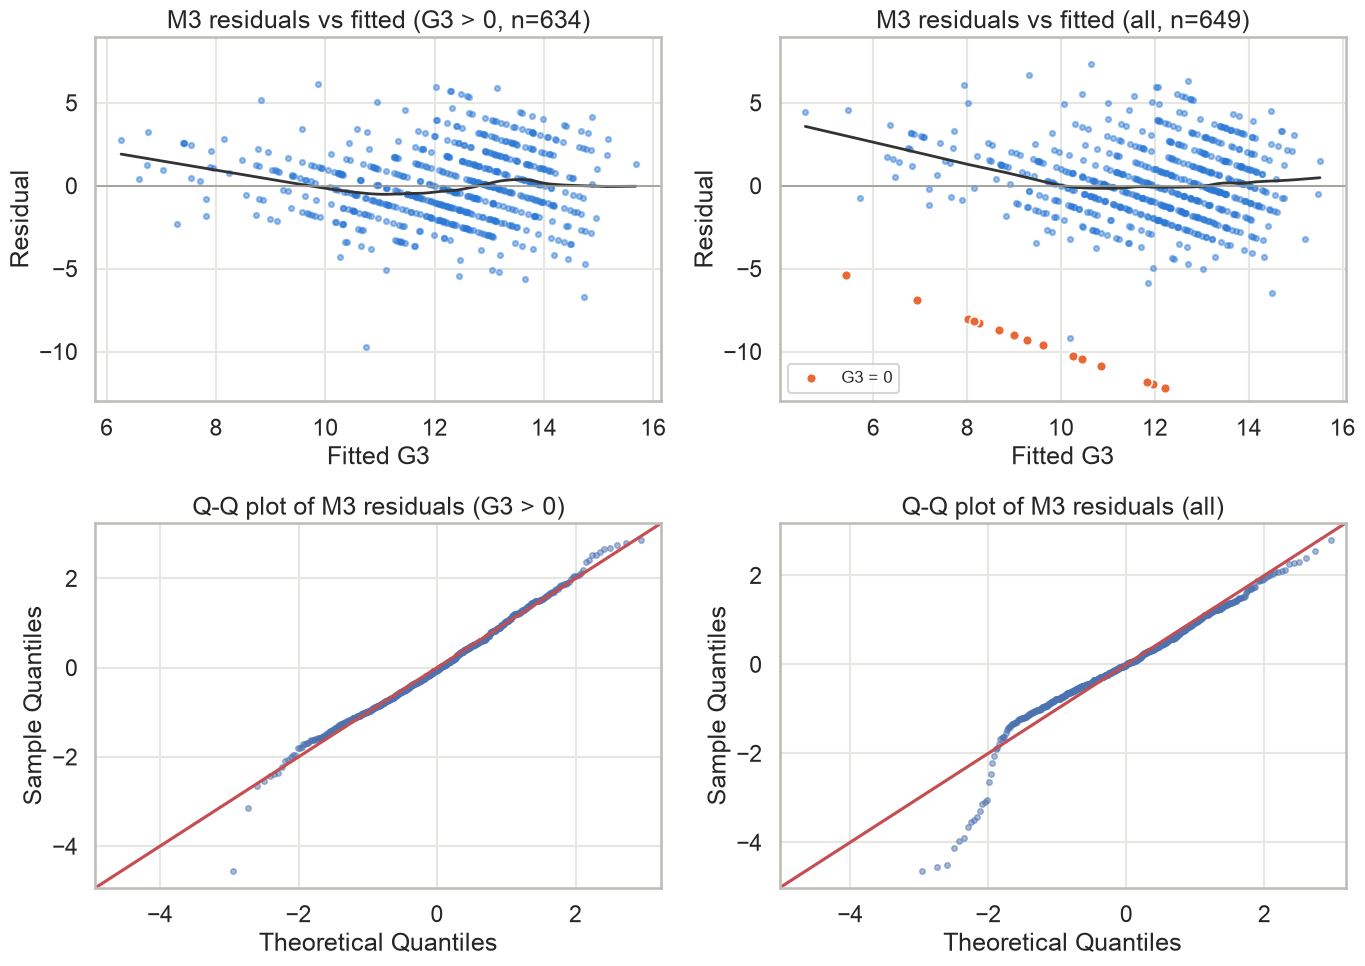

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, k in enumerate(["G3 > 0", "all"]):
    m = M3[k]; d = SAMPLES[k]
    gh = d.zero_grade.values
    ax = axes[0, j]
    ax.scatter(m.fittedvalues[~gh], m.resid[~gh], s=14, alpha=0.45, color=BLUE)
    if gh.any():
        ax.scatter(m.fittedvalues[gh], m.resid[gh], s=50, color=ORANGE, edgecolor="white", lw=1.2, label="G3 = 0")
        ax.legend(fontsize=12, loc="lower left")
    lw = sm.nonparametric.lowess(m.resid, m.fittedvalues, frac=0.4)
    ax.plot(lw[:, 0], lw[:, 1], color="#333", lw=2)
    ax.axhline(0, color=GREY, lw=1.2)
    ax.set(xlabel="Fitted G3", ylabel="Residual", title=f"M3 residuals vs fitted ({k}, n={int(m.nobs)})", ylim=(-13, 9))
    ax = axes[1, j]
    sm.qqplot(m.resid, line="45", fit=True, ax=ax, markersize=4, alpha=0.5, color=BLUE)
    ax.set(title=f"Q-Q plot of M3 residuals ({k})")
savefig(fig, "30_residuals_fitted_qq")

for k, m in M3.items():
    jb, jbp, sk, ku = jarque_bera(m.resid)
    print(f"{k:6s}: Jarque-Bera = {jb:.1f}, p = {jbp:.2g}, skew = {sk:.2f}, kurtosis = {ku:.2f}")
    score.append({"check": "Normality of residuals, Jarque-Bera (M3)", "sample": k, "statistic": jb, "p_value": jbp,
                  "detail": f"skew {sk:.2f}, kurtosis {ku:.2f}"})

**Interpretation:** Without the zero-grade cases, the residuals are well behaved: the residual-vs-fitted cloud has no funnel, the lowess line stays close to 0 except for a mild upward bend at the lowest fitted values (below about 9), and the Q-Q plot is close to the line (Jarque-Bera p = 0.054, skew 0.05, kurtosis 3.46). One G3 > 0 student sits near -10 (the single student with G3 = 1). With the zero-grade cases included, the 15 orange points form a separate diagonal band (G3 = 0 means residual = -fitted), which produces the heavy left tail in the Q-Q plot (skew -0.90, kurtosis 6.35, Jarque-Bera p = 7e-86). The diagonal stripes in both panels come from G3 being a whole number.

## 4. Influence: Cook's distance and leverage
Rule of thumb: Cook's D > 4/n flags a point worth inspecting; D > 1 would mean one point alone moves the fit
substantially.

In [6]:
infl = {}
for k, m in M3.items():
    inf = m.get_influence()
    cd = inf.cooks_distance[0]
    d = SAMPLES[k]
    t = pd.DataFrame({"cooks_d": cd, "leverage": inf.hat_matrix_diag, "stud_resid": inf.resid_studentized_external,
                      "zero_grade": d.zero_grade.values, "G3": d.G3.values, "absences": d.absences.values})
    infl[k] = t
    thr = 4 / len(d)
    top10 = t.nlargest(10, "cooks_d")
    print(f"{k:6s}: max Cook's D = {cd.max():.4f}; above 4/n ({thr:.4f}): {(cd > thr).sum()}; "
          f"zero-grade cases among them: {int(t[t.cooks_d > thr].zero_grade.sum())}; zero-grade cases in top 10: {int(top10.zero_grade.sum())}")
    score.append({"check": "Influence, Cook's distance (M3)", "sample": k, "statistic": cd.max(), "p_value": np.nan,
                  "detail": f"{(cd > thr).sum()} points > 4/n; zero-grade cases in top 10: {int(top10.zero_grade.sum())}; none > 1"
                            if cd.max() < 1 else f"{(cd > 1).sum()} points > 1"})
infl["all"].nlargest(10, "cooks_d").round(4)

G3 > 0: max Cook's D = 0.0368; above 4/n (0.0063): 35; zero-grade cases among them: 0; zero-grade cases in top 10: 0
all   : max Cook's D = 0.0492; above 4/n (0.0062): 37; zero-grade cases among them: 15; zero-grade cases in top 10: 8


,cooks_d,leverage,stud_resid,zero_grade,G3,absences
626,0.0492,0.0478,-4.6121,True,0,0
586,0.0416,0.0479,-4.2225,True,0,0
640,0.0394,0.0679,-3.3970,True,0,0
603,0.0348,0.0327,-4.7297,True,0,0
440,0.0274,0.0409,-3.7131,True,0,0
519,0.0267,0.0265,-4.6100,True,0,0
61,0.0224,0.0657,2.5994,False,16,0
637,0.0217,0.0282,-4.0128,True,0,0
172,0.0208,0.0345,-3.5347,False,1,0
639,0.0199,0.0324,-3.5658,True,0,0


           G3 > 0 (n=634)  drop Cook's D > 4/n (n=599)  p (trimmed)
studytime          0.3104                       0.3820       0.0002
log_abs           -0.4482                      -0.4333       0.0000
failures          -1.2327                      -1.3180       0.0000
saved figures/31_cooks_distance.png


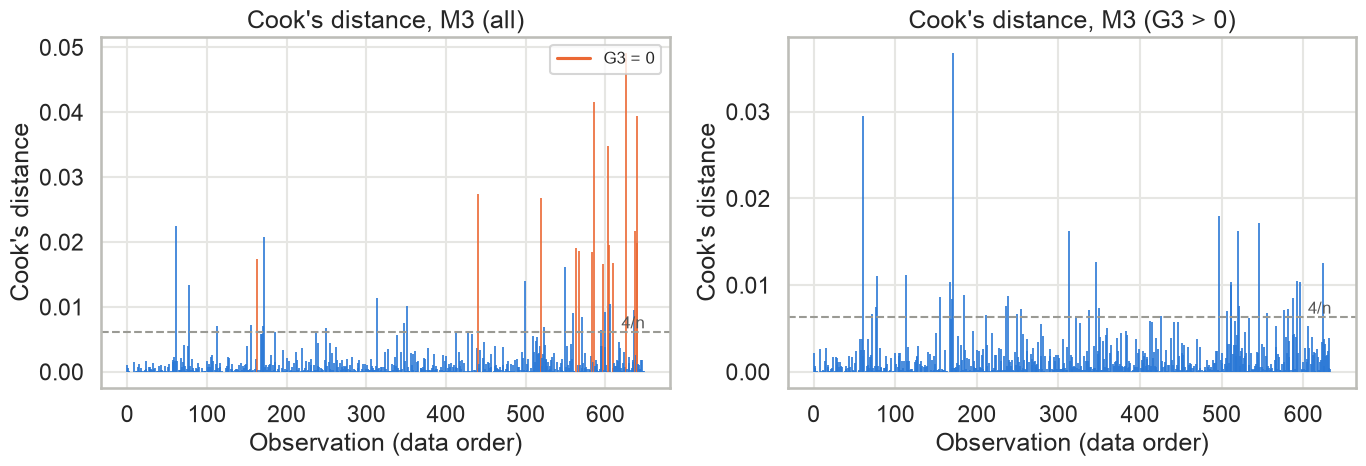

In [7]:
# How much does the main result move if the 4/n-flagged points are dropped (G3 > 0 sample)?
t = infl["G3 > 0"]
keep = t.cooks_d <= 4 / len(nz)
m_trim = smf.ols(F_M3, nz[keep.values]).fit(cov_type="HC3")
m_base = smf.ols(F_M3, nz).fit(cov_type="HC3")
print(pd.DataFrame({"G3 > 0 (n=%d)" % len(nz): m_base.params[["studytime", "log_abs", "failures"]],
                    "drop Cook's D > 4/n (n=%d)" % keep.sum(): m_trim.params[["studytime", "log_abs", "failures"]],
                    "p (trimmed)": m_trim.pvalues[["studytime", "log_abs", "failures"]]}).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, k in zip(axes, ["all", "G3 > 0"]):
    t = infl[k]
    ax.vlines(np.arange(len(t)), 0, t.cooks_d, color=np.where(t.zero_grade, ORANGE, BLUE), lw=1.2)
    ax.axhline(4 / len(t), color=GREY, ls="--", lw=1.5)
    ax.text(len(t), 4 / len(t), " 4/n", va="bottom", ha="right", color="#555", fontsize=12)
    ax.set(xlabel="Observation (data order)", ylabel="Cook's distance", title=f"Cook's distance, M3 ({k})")
axes[0].plot([], [], color=ORANGE, label="G3 = 0"); axes[0].legend(fontsize=12)
savefig(fig, "31_cooks_distance")

**Interpretation:** No single student dominates: the maximum Cook's distance is 0.049 (all) and 0.037 (G3 > 0), far below 1. In the full sample all 15 zero-grade cases exceed the 4/n cut-off and 8 of the top 10 are zero-grade cases, so the zero-grade cases are influential **as a group** (notebook 04) even though none of them is decisive alone, which is why Cook's distance by itself would not have caught them. In the sample without zero-grade cases, dropping all 35 points above 4/n leaves the results intact: study time 0.310 to 0.382 (p = 0.0002), log absences -0.448 to -0.433, failures -1.23 to -1.32.

## 5. Functional form: RESET, with log absences and with raw absences
Ramsey RESET adds powers of the fitted values; a significant F says some non-linearity is missing.

In [8]:
rs = []
for k, d in SAMPLES.items():
    for form, f in [("log(abs+1)", F_M3), ("raw absences", F_M3.replace("log_abs", "absences")),
                    ("M4, log(abs+1)", F_M4)]:
        m = smf.ols(f, d).fit()
        r2 = linear_reset(m, power=2, use_f=True)
        r3 = linear_reset(m, power=3, use_f=True)
        rs.append({"sample": k, "spec": form, "RESET2_F": r2.fvalue, "RESET2_p": r2.pvalue,
                   "RESET23_F": r3.fvalue, "RESET23_p": r3.pvalue, "AIC": m.aic})
        score.append({"check": f"Functional form, RESET power 2 ({'M4' if form.startswith('M4') else 'M3'}, {form.replace('M4, ', '')})",
                      "sample": k, "statistic": r2.fvalue, "p_value": r2.pvalue,
                      "detail": f"powers 2-3: F {r3.fvalue:.2f}, p {r3.pvalue:.3g}"})
rs = pd.DataFrame(rs).set_index(["sample", "spec"])
rs.round(5)

RESET2_F  RESET2_p  RESET23_F  RESET23_p         AIC
sample spec                                                                
G3 > 0 log(abs+1)      17.71111   0.00003   11.09549    0.00002  2804.19851
       raw absences    20.04656   0.00001   11.49384    0.00001  2808.98545
       M4, log(abs+1)   0.69097   0.40616    5.89141    0.00292  1710.25964
all    log(abs+1)      13.64499   0.00024    7.54320    0.00058  3137.49449
       raw absences    12.52810   0.00043    7.16307    0.00084  3136.17840
       M4, log(abs+1)  11.00634   0.00096    5.97002    0.00270  2149.25170

In [9]:
# Where could the non-linearity come from? Check (a) study time as categories, (b) the 0-20 bound
for k, d in SAMPLES.items():
    m = smf.ols(F_M3.replace("studytime", "C(studytime)"), d).fit()
    r = linear_reset(m, power=2, use_f=True)
    print(f"{k:6s} M3 with C(studytime): RESET F = {r.fvalue:.2f}, p = {r.pvalue:.3g}")
m = M3["G3 > 0"]
print("fitted range (G3 > 0):", round(m.fittedvalues.min(), 2), "to", round(m.fittedvalues.max(), 2))
print("mean residual by fitted-value quintile (G3 > 0):")
print(pd.Series(m.resid.values).groupby(pd.qcut(m.fittedvalues.values, 5), observed=True).mean().round(3))

G3 > 0 M3 with C(studytime): RESET F = 17.80, p = 2.83e-05
all    M3 with C(studytime): RESET F = 12.94, p = 0.000348
fitted range (G3 > 0): 6.26 to 15.68
mean residual by fitted-value quintile (G3 > 0):
(6.262, 10.874]    -0.042
(10.874, 12.133]   -0.301
(12.133, 12.823]   -0.012
(12.823, 13.576]    0.253
(13.576, 15.679]    0.103
dtype: float64


**Interpretation:** **Functional form is the one diagnostic M3 does not pass.** RESET (power 2) rejects for M3 on both samples and with either absence form: G3 > 0, log absences F = 17.7, p = 3e-5; raw absences F = 20.0, p = 1e-5; full sample p = 2.4e-4 and 4.3e-4. Switching from raw to log absences does not fix it (the log is better by AIC, 2804.2 vs 2809.0, but RESET is about the same), and neither does entering study time as categories (p = 2.8e-5). So the misspecification does not come from the absence or study-time coding. The residual means by fitted-value quintile (-0.04, -0.30, -0.01, +0.25, +0.10) and the lowess bend at low fitted values point to mild curvature, consistent with a bounded 0-20 grade scale and omitted interactions. The G1/G2 model on the sample without zero-grade cases passes RESET at power 2 (p = 0.41) but not at powers 2-3 (p = 0.003). This agrees with the pilot (p of about 2e-4 all, 3e-5 G3 > 0). **Reading:** the linear model is a reasonable approximation for the signs and rough sizes of the coefficients, but should not be presented as the true functional form. Say this openly on slide 7.

## 6. Autocorrelation: why it does not apply

**Why autocorrelation does not apply.** Autocorrelation means the error for one observation is correlated with the error for the *next* one in a natural order, usually time (this quarter's shock carries into next quarter). Our data are a single cross-section: 649 different students observed once, and the row order in the file carries no meaning (it is not a time sequence). There is no 'previous student' whose error could spill over, so the classical autocorrelation assumption, and tests like Durbin-Watson, have nothing to test. The cross-sectional analogue would be *clustering* (students in the same school or class sharing shocks). With only two schools we cannot estimate cluster-robust SEs reliably, so we include a school dummy and name clustering as a limitation. The cell below computes Durbin-Watson only to show that the number depends entirely on how the rows are arranged.

In [10]:
m = M3["G3 > 0"]
rng = np.random.default_rng(0)
dw = {"file order (as published)": durbin_watson(m.resid),
      "sorted by G3": durbin_watson(m.resid[np.argsort(nz.G3.values, kind="stable")]),
      "sorted by school, then G1": durbin_watson(m.resid[np.lexsort((nz.G1.values, nz.school.values))]),
      **{f"random shuffle {i+1}": durbin_watson(rng.permutation(m.resid.values)) for i in range(3)}}
print(pd.Series(dw).round(3))
score.append({"check": "Autocorrelation (Durbin-Watson)", "sample": "G3 > 0", "statistic": dw["file order (as published)"],
              "p_value": np.nan, "detail": f"not applicable (cross-section); DW sorted by G3 = {dw['sorted by G3']:.2f}, "
                                           "shows the statistic depends on arbitrary row order"})

file order (as published)    1.778
sorted by G3                 0.639
sorted by school, then G1    0.886
random shuffle 1             2.100
random shuffle 2             1.892
random shuffle 3             2.073
dtype: float64


**Interpretation:** The same residuals give a Durbin-Watson of 1.78 in file order, 1.89-2.10 after random shuffles, and 0.64 when the rows are sorted by G3 (or 0.89 sorted by school and G1). The 'autocorrelation' changes from none to strong just by sorting the spreadsheet, which shows that DW is meaningless for cross-sectional data. (Sorting by the outcome makes neighbouring residuals similar by construction.)

## 7. Endogeneity and simultaneity of study time

**Endogeneity and simultaneity of study time.** OLS gives a causal effect only if study time is uncorrelated with the error term. That is unlikely here, for three reasons. (1) *Reverse causality / simultaneity:* grades affect study time as well as the other way round. A student who did badly in period 1 may study more to recover, or may give up, so study time and G3 are jointly determined. This is a simultaneous-equations system (G3 = f(study time, ...) and study time = g(expected G3, ...)), and a single OLS equation mixes the two directions. (2) *Omitted variables:* motivation, ability and conscientiousness raise both study time and grades and are not measured. The controls (failures, wants higher education, sex) are only partial proxies, so the M3 coefficient probably still overstates the effect of studying itself. (3) *Measurement error:* study time is a self-reported 4-level category, which tends to bias the coefficient toward zero. Because (2) and (3) push in opposite directions, the overall sign of the bias is not known. The textbook remedy is two-stage least squares with an instrument that shifts study time but has no direct effect on grades (for example a random assignment of homework load or of travel time to a study centre). The dataset contains no credible instrument (travel time, for example, plausibly affects grades directly through fatigue and absences), so we name the problem and interpret every study-time coefficient as an **association**, not a causal effect. Separately, G1/G2 in M4 are 'bad controls' because they are partly *outcomes* of studying, so M4 understates the total effect.

## 8. Diagnostics scorecard

In [11]:
def verdict(r):
    c, p, s = r["check"], r["p_value"], r["statistic"]
    if c.startswith("Multicollinearity"):
        return ("green", "no action") if s < 5 else ("amber", "inspect")
    if c.startswith("Heteroskedasticity"):
        if p >= .05: return ("green", "none needed; HC3 used anyway")
        return ("amber", "HC3 robust SEs") if p >= .01 else ("red", "HC3 robust SEs")
    if c.startswith("HC3"):
        return ("green", "report HC3 throughout")
    if c.startswith("Normality"):
        return ("amber", "large n, CLT; inference via HC3") if p < .05 else ("green", "no action")
    if c.startswith("Influence"):
        return ("green", "no single point dominates") if s < 1 else ("red", "inspect")
    if c.startswith("Functional"):
        return ("green", "no action") if p >= .05 else ("amber", "report openly; bounded 0-20 outcome")
    if c.startswith("Autocorrelation"):
        return ("n/a", "cross-sectional data")
    return ("", "")

sc = pd.DataFrame(score)
sc[["light", "action"]] = sc.apply(lambda r: pd.Series(verdict(r)), axis=1)
sc = sc[["check", "sample", "statistic", "p_value", "light", "action", "detail"]]
sc.to_csv(RES / "diagnostics_scorecard.csv", index=False)
print("saved results/diagnostics_scorecard.csv")
with pd.option_context("display.max_colwidth", 70):
    display(sc.round(4))

saved results/diagnostics_scorecard.csv


,check,sample,statistic,p_value,light,action,detail
0,Multicollinearity (max VIF),G3 > 0,1.9890,NaN,green,no action,"max = Walc; Medu 1.92, Fedu 1.78, Dalc 1.74, Walc 1.99"
1,Multicollinearity (max VIF),all,1.9707,NaN,green,no action,"max = Walc; Medu 1.91, Fedu 1.78, Dalc 1.71, Walc 1.97"
2,"Heteroskedasticity, Breusch-Pagan (M3)",G3 > 0,24.1564,0.2356,green,none needed; HC3 used anyway,LM test on OLS residuals
3,"Heteroskedasticity, White (M3)",G3 > 0,257.8220,0.0451,amber,HC3 robust SEs,"special form (yhat, yhat^2): LM 4.4, p 0.112"
4,"Heteroskedasticity, Breusch-Pagan (M3)",all,86.1164,0.0000,red,HC3 robust SEs,LM test on OLS residuals
5,"Heteroskedasticity, White (M3)",all,347.3069,0.0000,red,HC3 robust SEs,"special form (yhat, yhat^2): LM 11.2, p 0.00371"
6,"Heteroskedasticity, Breusch-Pagan (M4)",G3 > 0,39.6632,0.0118,amber,HC3 robust SEs,LM test on OLS residuals
7,"Heteroskedasticity, White (M4)",G3 > 0,385.7704,0.0000,red,HC3 robust SEs,"special form (yhat, yhat^2): LM 2.7, p 0.253"
8,"Heteroskedasticity, Breusch-Pagan (M4)",all,55.0070,0.0001,red,HC3 robust SEs,LM test on OLS residuals
9,"Heteroskedasticity, White (M4)",all,399.2739,0.0000,red,HC3 robust SEs,"special form (yhat, yhat^2): LM 22.2, p 1.48e-05"


## Pilot check (readme section 5)

In [12]:
P, N = het.loc[("M3", "all")], het.loc[("M3", "G3 > 0")]
checks = {
    "max VIF (2.0, Walc) all": (round(vifs["all"].max(), 1), 2.0),
    "BP LM M3 all (86.1)": (P.BP_LM, 86.1),
    "BP LM M3 G3>0 (24.2)": (N.BP_LM, 24.2),
    "BP p M3 G3>0 (0.24)": (N.BP_p, 0.24),
    "RESET p M3 all (2e-4)": (rs.loc[("all", "log(abs+1)"), "RESET2_p"], 2e-4),
    "RESET p M3 G3>0 (3e-5)": (rs.loc[("G3 > 0", "log(abs+1)"), "RESET2_p"], 3e-5),
}
chk = pd.DataFrame([{"check": k, "notebook": float(v), "pilot": p,
                     "match": (abs(float(v) - p) <= 0.006 + 0.01 * abs(p)) if p > 0.01 else (0.5 < float(v) / p < 2)}
                    for k, (v, p) in checks.items()])
print("VIF max variable (all):", vifs["all"].idxmax(), "| (G3 > 0):", vifs["G3 > 0"].idxmax())
print("all match:", chk.match.all())
chk

VIF max variable (all): Walc | (G3 > 0): Walc
all match: True


,check,notebook,pilot,match
0,"max VIF (2.0, Walc) all",2.000000,2.00000,True
1,BP LM M3 all (86.1),86.116430,86.10000,True
2,BP LM M3 G3>0 (24.2),24.156374,24.20000,True
3,BP p M3 G3>0 (0.24),0.235628,0.24000,True
4,RESET p M3 all (2e-4),0.000240,0.00020,True
5,RESET p M3 G3>0 (3e-5),0.000030,0.00003,True


## Summary

**Scorecard for M3 (controls model), sample without zero-grade cases (G3 > 0, n = 634), with the full sample in brackets:**

- Multicollinearity: **green**. Max VIF 1.99, Walc (1.97). Medu/Fedu (r = 0.65) and Dalc/Walc (r = 0.62) are correlated pairs, but their VIFs are under 2.
- Heteroskedasticity: **green on BP, amber on White** (BP p = 0.24; special White p = 0.11; full White p = 0.045). [Full sample: **red**, BP p = 3.5e-10.] HC3 is used throughout and changes the SEs by at most 12%.
- Residuals and normality: **green** (JB p = 0.054). [Full sample: heavy left tail, all of it from the zero-grade cases.]
- Influence: **green**. Max Cook's D 0.037; dropping all 35 points above 4/n leaves the conclusions unchanged.
- Functional form (RESET): **amber**. It rejects (p = 3e-5) with log or raw absences and with categorical study time. Report it openly; a likely cause is the bounded 0-20 scale.
- Autocorrelation: **n/a** (cross-section; DW goes from 1.78 to 0.64 just by sorting rows).
- Endogeneity: **caveat**. Study time is probably endogenous (simultaneity, omitted motivation); there is no instrument, so the coefficients are associations.

**Agreement with the pilot:** VIF about 2.0 (Walc), BP 86.1 vs 24.2 (p = 0.24), and RESET p of about 2e-4 / 3e-5 are all reproduced. **Addition to the readme:** the G1/G2 model (M4) remains heteroskedastic without the zero-grade cases (BP p = 0.012), so 'the heteroskedasticity goes away' applies to M3 only, and the full White test on M3 is borderline (p = 0.045).